# IoT intrusion detection: metaheuristic optimization (GA, PSO, ACO)
Phase 2 of the CICIoT2023 project. Each of the four models is tuned (features and hyperparameters together) by GA, PSO, ACO and a random-search control with an identical budget, and compared with the baselines of `iot_ids.ipynb`.

## Results at a glance

In [1]:
import pandas as pd, numpy as np, json, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Markdown
O = Path("results/optimization")
M = pd.read_csv(O / "optimization_metrics.csv")
cols = ["macro_f1", "accuracy", "precision", "recall", "fpr"]
OPT = {"baseline": 0, "ga": 1, "pso": 2, "aco": 3, "random": 4}
M["o"] = M.optimizer.map(OPT)
M = M.sort_values(["task", "model", "o"]).reset_index(drop=True)
b = M[M.optimizer == "baseline"].set_index(["model", "task"])[cols]
for c in cols:
    M["d_" + c] = M[c].values - [b.loc[(m, t), c] for m, t in zip(M.model, M.task)]
T = M[["model_id", "task", "optimizer"] + cols + ["d_" + c for c in cols]]

def css(df):
    out = pd.DataFrame("", index=df.index, columns=df.columns)
    for (m, t), g in M.groupby(["model", "task"]):
        for c in cols:
            best = g[c].min() if c == "fpr" else g[c].max()
            out.loc[g.index[g[c] == best], c] = "background-color:#b7e1b7;font-weight:bold"
            for i in g.index:
                d = M.loc[i, "d_" + c]
                if M.loc[i, "optimizer"] == "baseline" or d == 0: continue
                good = d < 0 if c == "fpr" else d > 0
                out.loc[i, "d_" + c] = "background-color:%s" % ("#b7e1b7" if good else "#f4b6b6")
    return out

sty = (T.style.apply(css, axis=None).format({**{c: "{:.4f}" for c in cols}, **{"d_" + c: "{:+.4f}" for c in cols}}).hide(axis="index")
       .set_caption("Test-set metrics, single final model (seed 42). Green bold = best per model/task; delta columns vs baseline: green better, red worse (lower FPR is better)."))
display(sty)

model_id,task,optimizer,macro_f1,accuracy,precision,recall,fpr,d_macro_f1,d_accuracy,d_precision,d_recall,d_fpr
dt_binary,binary,baseline,0.7854,0.9767,0.7873,0.7836,0.4211,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000
dt_binary_ga,binary,ga,0.7939,0.9791,0.8187,0.7729,0.4455,+0.0085,+0.0024,+0.0313,-0.0106,+0.0244
dt_binary_pso,binary,pso,0.7912,0.9795,0.8285,0.7620,0.4684,+0.0058,+0.0028,+0.0411,-0.0215,+0.0473
dt_binary_aco,binary,aco,0.7957,0.9796,0.8265,0.7704,0.4512,+0.0102,+0.0029,+0.0392,-0.0131,+0.0301
dt_binary_random,binary,random,0.7913,0.9791,0.8204,0.7673,0.4571,+0.0058,+0.0024,+0.0330,-0.0163,+0.0360
mlp_binary,binary,baseline,0.7800,0.9793,0.8333,0.7421,0.5091,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000
mlp_binary_ga,binary,ga,0.7657,0.9784,0.8259,0.7251,0.5432,-0.0143,-0.0009,-0.0073,-0.0170,+0.0341
mlp_binary_pso,binary,pso,0.7813,0.9787,0.8203,0.7513,0.4897,+0.0013,-0.0006,-0.0130,+0.0091,-0.0194
mlp_binary_aco,binary,aco,0.7843,0.9788,0.8192,0.7568,0.4784,+0.0044,-0.0005,-0.0141,+0.0146,-0.0307
mlp_binary_random,binary,random,0.7719,0.9786,0.8259,0.7341,0.5250,-0.0081,-0.0007,-0.0074,-0.0081,+0.0160


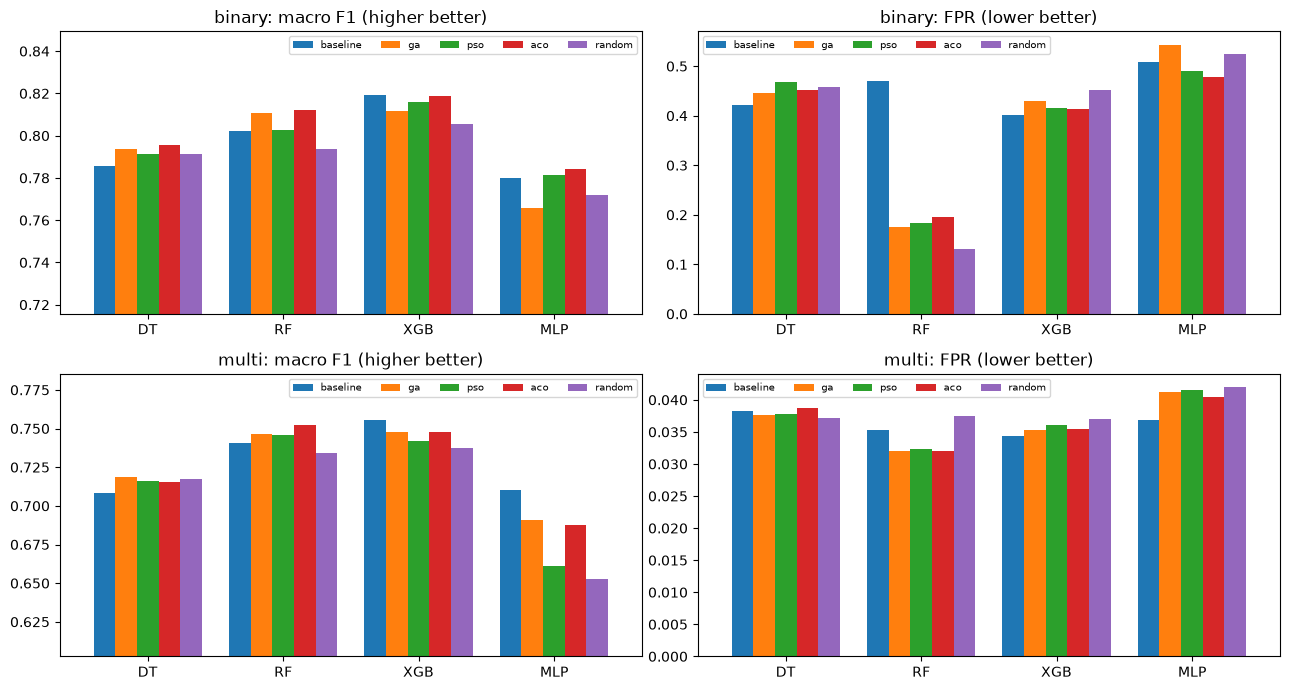

In [2]:
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
names = {"dt": "DT", "rf": "RF", "xgb": "XGB", "mlp": "MLP"}
for r, t in enumerate(["binary", "multi"]):
    for k, (c, lab) in enumerate([("macro_f1", "macro F1 (higher better)"), ("fpr", "FPR (lower better)")]):
        p = M[M.task == t].pivot(index="model", columns="optimizer", values=c).loc[["dt", "rf", "xgb", "mlp"], list(OPT)]
        p.rename(index=names).plot.bar(ax=ax[r, k], rot=0, width=0.8)
        ax[r, k].set_title(f"{t}: {lab}"); ax[r, k].set_xlabel(""); ax[r, k].legend(fontsize=7, ncol=5)
        if c == "macro_f1": ax[r, k].set_ylim(max(0, p.values.min() - 0.05), min(1, p.values.max() + 0.03))
plt.tight_layout(); plt.show()

## Method
**Encoding (shared by GA, PSO, ACO and random search).** One vector in [0,1]^(39+h): the first 39 entries are feature switches (kept if > 0.5; if fewer than 5 are kept the 5 largest entries are used), followed by *h* hyperparameter entries mapped to the ranges below (integers rounded, `log` ranges mapped on a log scale, categories by equal-width bins).

**Fitness.** macro F1 on a fixed stratified 50,000-row *validation* subsample, for a model trained on a fixed stratified 100,000-row *training* subsample (rare classes keep at least 200 rows), minus 0.001 x (fraction of features used). The MLP uses the training-fitted scaler and its early stopping looks at a 10% hold-out of the training subsample. The optimizer code never reads the held-out test split; the final winners are retrained on the full training split and scored once on test.

**Optimizers.** Same population / swarm / ant count (20), same seed, same first 20 random candidates and the same budget of *unique* evaluations per model and task. GA: tournament(3), BLX-0.5 crossover, Gaussian mutation, 2 elites. PSO: inertia 0.72, c1 = c2 = 1.49. ACO: ACO for continuous domains (ACOR: solution archive of 20, rank weights, Gaussian kernel sampling), an adaptation of ACO to continuous variables, not the classical discrete one. Random search: uniform draws with the same budget.

In [3]:
import sys; sys.path.insert(0, ".")
from optimization import core
rows = [{"model": m, "parameter": s[0], "type": s[1], "range / choices": (f"{s[2]} .. {s[3]}" if s[1] != "cat" else str(s[2]))} for m, v in core.HP.items() for s in v]
display(pd.DataFrame(rows))
R = pd.read_csv(O / "search_summary.csv")
bud = R.groupby(["task", "model"]).agg(budget=("budget", "first"), evals_per_method=("n_evals", "unique"), mean_eval_s=("mean_eval_s", "mean")).reset_index()
bud["evals_per_method"] = bud.evals_per_method.map(lambda v: ", ".join(map(str, v)))
display(bud.style.format({"mean_eval_s": "{:.2f}"}).hide(axis="index").set_caption("Evaluation budget (identical for GA, PSO, ACO, random)"))

,model,parameter,type,range / choices
0,dt,max_depth,int,3 .. 40
1,dt,min_samples_split,int,2 .. 50
2,dt,min_samples_leaf,int,1 .. 30
3,dt,criterion,cat,"['gini', 'entropy', 'log_loss']"
4,dt,class_weight,cat,"[None, 'balanced']"
5,rf,n_estimators,int,10 .. 150
6,rf,max_depth,int,3 .. 30
7,rf,min_samples_leaf,int,1 .. 20
8,rf,max_features,cat,"['sqrt', 'log2', 0.5]"
9,rf,class_weight,cat,"[None, 'balanced', 'balanced_subsample']"


task,model,budget,evals_per_method,mean_eval_s
binary,dt,800,800,0.48
binary,mlp,600,600,13.65
binary,rf,800,"800, 689",5.09
binary,xgb,800,800,1.35
multi,dt,800,800,1.07
multi,mlp,580,580,13.10
multi,rf,800,800,12.95
multi,xgb,650,650,14.83


## Convergence
Best fitness so far (validation-subsample macro F1 minus the 0.001 feature penalty) against the number of unique evaluations; y axis starts just below the best value after the first 20 shared random candidates.

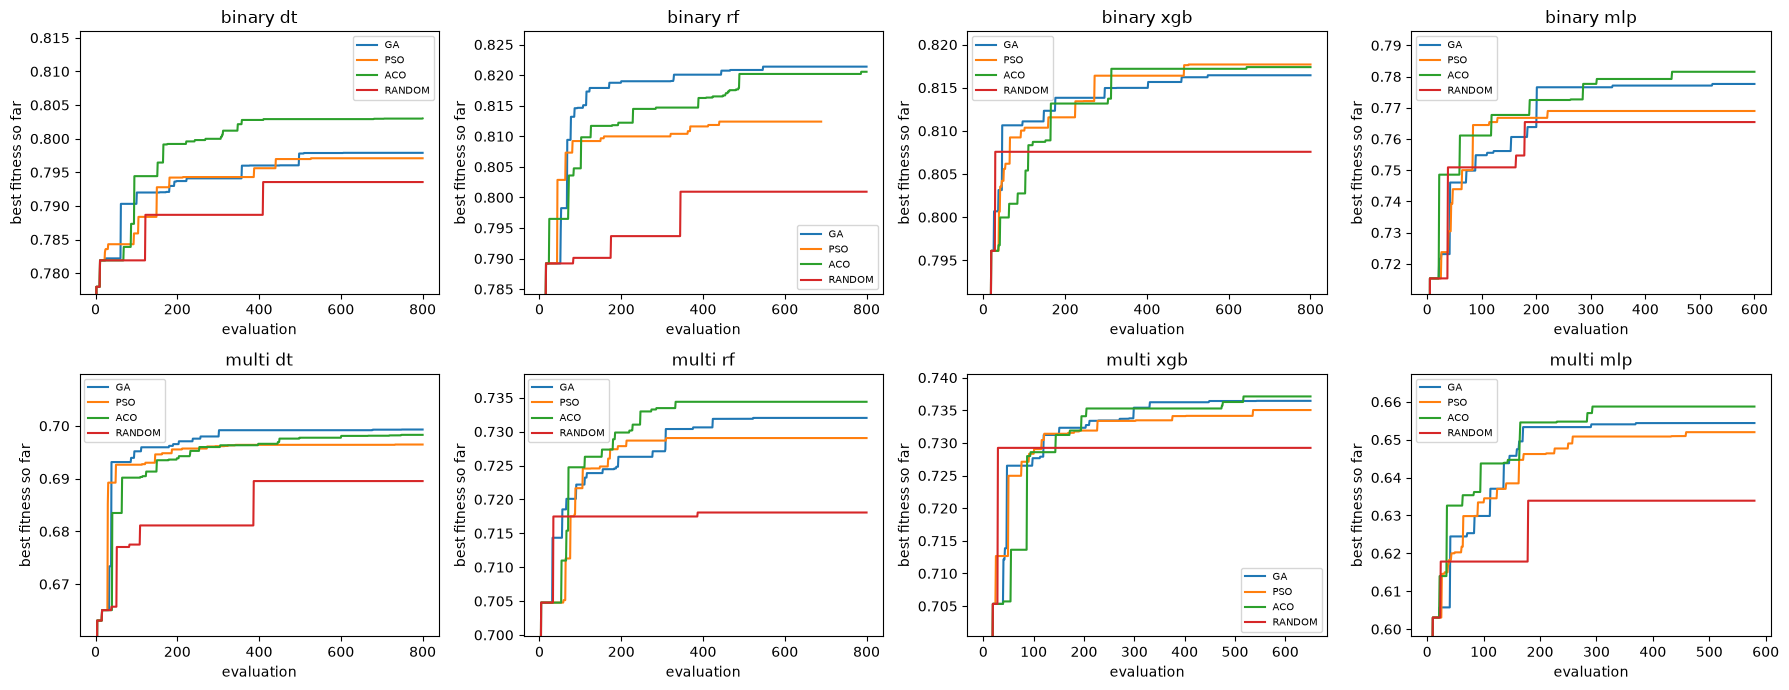

In [4]:
fig, ax = plt.subplots(2, 4, figsize=(18, 7))
for r, t in enumerate(["binary", "multi"]):
    for k, m in enumerate(["dt", "rf", "xgb", "mlp"]):
        for o in ["ga", "pso", "aco", "random"]:
            h = json.load(open(O / "runs" / f"{t}_{m}_{o}.json"))["history"]
            ax[r, k].plot([e["eval"] for e in h], [e["best_so_far"] for e in h], label=o.upper())
        ax[r, k].set_title(f"{t} {m}"); ax[r, k].set_xlabel("evaluation"); ax[r, k].set_ylabel("best fitness so far")
        # zoom the y axis on the last 80% of the curve so differences are visible
        lo = min(json.load(open(O / "runs" / f"{t}_{m}_{o}.json"))["history"][19]["best_so_far"] for o in ["ga", "pso", "aco", "random"])
        ax[r, k].set_ylim(lo - 0.005, None)
        ax[r, k].legend(fontsize=7)
plt.tight_layout(); plt.show()

## Selected features and hyperparameters of each winner

In [5]:
import pyarrow.parquet as pq
names = [n for n in pq.read_schema("data_processed/clean.parquet").names if not n.startswith("y_")]
rows = []
for o in ["ga", "pso", "aco", "random"]:
    for t in ["binary", "multi"]:
        for m in ["dt", "rf", "xgb", "mlp"]:
            r = json.load(open(O / "runs" / f"{t}_{m}_{o}.json"))
            rows.append({"task": t, "model": m, "optimizer": o, "fitness": r["best_fitness"], "n_features": sum(r["mask"]),
                         "features": ", ".join(n for n, k in zip(names, r["mask"]) if k), "hyperparameters": str(r["hp"])})
W = pd.DataFrame(rows).sort_values(["task", "model", "optimizer"])
pd.set_option("display.max_colwidth", 400)
display(W.style.format({"fitness": "{:.4f}"}).hide(axis="index"))
freq = pd.DataFrame({t: pd.Series(np.sum([json.load(open(O / "runs" / f"{t}_{m}_{o}.json"))["mask"] for m in ["dt","rf","xgb","mlp"] for o in ["ga","pso","aco","random"]], axis=0), index=names) for t in ["binary", "multi"]})
display(freq.sort_values("multi", ascending=False).head(12).style.set_caption("How often a feature is kept across the 16 winners per task (max 16)"))

task,model,optimizer,fitness,n_features,features,hyperparameters
binary,dt,aco,0.8030,21,"Header_Length, Protocol Type, Time_To_Live, Rate, fin_flag_number, syn_flag_number, psh_flag_number, ack_count, fin_count, HTTPS, TCP, UDP, ICMP, IGMP, IPv, Min, Max, Std, Tot size, IAT, Number","{'max_depth': 11, 'min_samples_split': 50, 'min_samples_leaf': 8, 'criterion': 'gini', 'class_weight': None}"
binary,dt,ga,0.7979,17,"Header_Length, Time_To_Live, fin_flag_number, psh_flag_number, ack_count, syn_count, fin_count, rst_count, HTTP, HTTPS, DHCP, LLC, Max, AVG, Std, Tot size, Number","{'max_depth': 9, 'min_samples_split': 21, 'min_samples_leaf': 5, 'criterion': 'log_loss', 'class_weight': None}"
binary,dt,pso,0.7971,23,"Protocol Type, Time_To_Live, fin_flag_number, psh_flag_number, ack_flag_number, ack_count, fin_count, rst_count, HTTP, HTTPS, DNS, UDP, ARP, ICMP, IGMP, IPv, LLC, Tot sum, Max, AVG, Std, Tot size, IAT","{'max_depth': 12, 'min_samples_split': 45, 'min_samples_leaf': 8, 'criterion': 'entropy', 'class_weight': None}"
binary,dt,random,0.7935,21,"Header_Length, Time_To_Live, Rate, syn_flag_number, rst_flag_number, psh_flag_number, cwr_flag_number, syn_count, fin_count, rst_count, HTTPS, SSH, DHCP, ICMP, IGMP, IPv, Tot sum, Max, Tot size, IAT, Number","{'max_depth': 9, 'min_samples_split': 34, 'min_samples_leaf': 7, 'criterion': 'entropy', 'class_weight': None}"
binary,mlp,aco,0.7815,23,"Header_Length, Time_To_Live, Rate, fin_flag_number, syn_flag_number, psh_flag_number, ece_flag_number, cwr_flag_number, ack_count, syn_count, fin_count, HTTP, HTTPS, DNS, SSH, TCP, UDP, DHCP, IGMP, Tot sum, IAT, Number, Variance","{'lr': 0.001985, 'dropout': 0.1274, 'batch': 512, 'hidden': [127, 88, 112]}"
binary,mlp,ga,0.7776,27,"Header_Length, Time_To_Live, Rate, fin_flag_number, syn_flag_number, rst_flag_number, psh_flag_number, ece_flag_number, syn_count, fin_count, rst_count, HTTP, Telnet, SMTP, IRC, TCP, DHCP, ARP, ICMP, IGMP, IPv, Min, Max, AVG, Std, Tot size, IAT","{'lr': 0.00903, 'dropout': 0.0021, 'batch': 2048, 'hidden': [128, 73]}"
binary,mlp,pso,0.7690,19,"Header_Length, Time_To_Live, Rate, fin_flag_number, syn_flag_number, rst_flag_number, psh_flag_number, ece_flag_number, ack_count, HTTP, DNS, Telnet, SMTP, IRC, TCP, LLC, Tot sum, Std, Number","{'lr': 0.0008021, 'dropout': 0.0, 'batch': 256, 'hidden': [102, 89, 16]}"
binary,mlp,random,0.7654,23,"Header_Length, Protocol Type, Time_To_Live, Rate, fin_flag_number, rst_flag_number, psh_flag_number, cwr_flag_number, ack_count, syn_count, HTTP, HTTPS, DNS, SSH, IRC, TCP, DHCP, ARP, IPv, Min, Max, AVG, Number","{'lr': 0.001989, 'dropout': 0.1746, 'batch': 256, 'hidden': [83, 50, 66]}"
binary,rf,aco,0.8206,18,"Header_Length, Time_To_Live, fin_flag_number, syn_flag_number, psh_flag_number, ack_count, HTTPS, DNS, SMTP, TCP, UDP, DHCP, IGMP, IPv, Min, Max, AVG, IAT","{'n_estimators': 91, 'max_depth': 30, 'min_samples_leaf': 2, 'max_features': 'log2', 'class_weight': 'balanced_subsample'}"
binary,rf,ga,0.8214,20,"Header_Length, Time_To_Live, Rate, fin_flag_number, syn_flag_number, psh_flag_number, ack_flag_number, ece_flag_number, ack_count, HTTPS, DNS, Telnet, SSH, IRC, UDP, IGMP, Min, Max, AVG, Tot size","{'n_estimators': 130, 'max_depth': 30, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}"


,binary,multi
Time_To_Live,16,16
HTTPS,14,16
SSH,8,16
Max,14,15
Min,11,15
Header_Length,15,15
psh_flag_number,15,14
HTTP,8,14
rst_flag_number,8,13
DNS,10,13


## Resources before and after, and cost of the search

In [6]:
B = pd.read_csv("results/benchmark_docker.csv").set_index("model_id")
N = pd.read_csv(O / "benchmark_docker.csv").set_index("model_id")
rows = []
for _, r in M.iterrows():
    mid, base = r.model_id, f"{r.model}_{r.task}"
    src = B if r.optimizer == "baseline" else N
    x = src.loc[mid] if mid in src.index else None
    oom = x is None or str(x.get("oom")) == "True" or str(x.get("failed")) == "True"
    bx = B.loc[base]
    rows.append({"model_id": mid, "optimizer": r.optimizer, "size_kb": np.nan if oom else x.size_kb, "peak_rss_mb": np.nan if oom else x.peak_rss_mb,
                 "lat_median_ms": np.nan if oom else x.lat_median_ms, "thr_b1024_per_s": np.nan if oom else x.throughput_b1024_per_s,
                 "status": "OOM/failed at 1 GB" if oom else "ok"})
Rs = pd.DataFrame(rows)
Rs["size_x_baseline"] = Rs.size_kb / Rs.model_id.map(lambda i: Rs.loc[Rs.model_id == i.split("_")[0] + "_" + i.split("_")[1], "size_kb"].iloc[0])
Rs["lat_x_baseline"] = Rs.lat_median_ms / Rs.model_id.map(lambda i: Rs.loc[Rs.model_id == i.split("_")[0] + "_" + i.split("_")[1], "lat_median_ms"].iloc[0])
display(Rs.style.format({"size_kb": "{:.1f}", "peak_rss_mb": "{:.1f}", "lat_median_ms": "{:.4f}", "thr_b1024_per_s": "{:,.0f}", "size_x_baseline": "{:.2f}", "lat_x_baseline": "{:.2f}"}).hide(axis="index")
        .set_caption("Docker --cpus=1 --memory=1g. Baseline rows come from the original benchmark (results/benchmark_docker.csv). A CPU utilisation column is omitted: it is ~100% for every model (see REPORT.md)."))
R = pd.read_csv(O / "search_summary.csv")
cost = R.groupby(["task", "model", "optimizer"]).agg(evals=("n_evals", "first"), cpu_s=("cpu_s", "first"), wall_s=("wall_s", "first"), mean_eval_s=("mean_eval_s", "first"), best_found_at_eval=("eval_of_best", "first")).reset_index()
display(cost.style.format({"cpu_s": "{:.0f}", "wall_s": "{:.0f}", "mean_eval_s": "{:.2f}"}).hide(axis="index").set_caption("Optimization cost per run (4 runs shared the CPU, so wall time includes contention; cpu_s is the process CPU time)"))
print("total optimization CPU hours:", round(R.cpu_s.sum() / 3600, 1), " max wall per combo (h):", round(R.groupby(["task", "model"]).wall_s.max().sum() / 3600, 1))

model_id,optimizer,size_kb,peak_rss_mb,lat_median_ms,thr_b1024_per_s,status,size_x_baseline,lat_x_baseline
dt_binary,baseline,718.5,131.3,0.1613,"4,455,632",ok,1.00,1.00
dt_binary_ga,ga,28.1,132.5,0.0955,"6,527,532",ok,0.04,0.59
dt_binary_pso,pso,65.2,132.7,0.0951,"5,709,586",ok,0.09,0.59
dt_binary_aco,aco,53.4,132.3,0.0926,"6,206,775",ok,0.07,0.57
dt_binary_random,random,26.3,132.4,0.0939,"6,335,948",ok,0.04,0.58
mlp_binary,baseline,183.7,565.7,1.8631,"403,029",ok,1.00,1.00
mlp_binary_ga,ga,183.6,577.6,2.1767,"344,496",ok,1.00,1.17
mlp_binary_pso,pso,179.4,575.6,2.4426,"318,227",ok,0.98,1.31
mlp_binary_aco,aco,323.2,577.5,2.8315,"254,824",ok,1.76,1.52
mlp_binary_random,random,150.2,577.8,2.8650,"285,470",ok,0.82,1.54


task,model,optimizer,evals,cpu_s,wall_s,mean_eval_s,best_found_at_eval
binary,dt,aco,800,363,368,0.43,800
binary,dt,ga,800,306,311,0.36,606
binary,dt,pso,800,541,548,0.66,527
binary,dt,random,800,392,397,0.47,410
binary,mlp,aco,600,16882,9797,16.29,449
binary,mlp,ga,600,10219,6353,10.54,523
binary,mlp,pso,600,14304,9619,16.00,221
binary,mlp,random,600,10464,7080,11.76,179
binary,rf,aco,800,13259,3923,4.86,787
binary,rf,ga,800,16544,4758,5.91,547


total optimization CPU hours: 127.6  max wall per combo (h): 14.1


## Seed noise

In [7]:
S = pd.read_csv(O / "optimization_seed_stability.csv")
display(S.style.format({"macro_f1_mean": "{:.4f}", "macro_f1_std": "{:.4f}"}).hide(axis="index").set_caption("Final configuration retrained with seeds 42, 43, 44 (split fixed); mean and sample SD of test macro F1"))

task,model,optimizer,macro_f1_mean,macro_f1_std,values
binary,dt,baseline,0.7846,0.0008,"[0.7854, 0.7838, 0.7847]"
binary,dt,ga,0.7939,0.0000,"[0.7939, 0.794, 0.794]"
binary,dt,pso,0.7912,0.0000,"[0.7912, 0.7912, 0.7912]"
binary,dt,aco,0.7957,0.0000,"[0.7957, 0.7956, 0.7957]"
binary,dt,random,0.7913,0.0000,"[0.7913, 0.7913, 0.7913]"
binary,rf,baseline,0.8020,0.0006,"[0.8021, 0.8013, 0.8025]"
binary,rf,ga,0.8096,0.0011,"[0.8106, 0.8097, 0.8085]"
binary,rf,pso,0.8040,0.0011,"[0.8027, 0.8043, 0.8049]"
binary,rf,aco,0.8113,0.0008,"[0.812, 0.8115, 0.8105]"
binary,rf,random,0.7933,0.0006,"[0.7935, 0.7926, 0.7938]"


## What happened
Generated from `optimization_metrics.csv` and `optimization_seed_stability.csv`. A gain smaller than two seed standard deviations (the larger of baseline and winner) is called noise; seeds change training randomness only, the data split is fixed, so true uncertainty is larger. Selection used validation-subsample fitness only, so a winner can lose on test.

- **binary dt**: baseline macro F1 0.7854; best optimizer ACO 0.7957 (+0.0102); the gain is larger than 2x the larger seed SD (0.0008); note seed SD covers training randomness only, not split-to-split variation. It beat random search (0.7913) by +0.0044. FPR baseline 0.4211 vs ACO 0.4512. GA/PSO/ACO that did not beat the baseline: none.
- **binary rf**: baseline macro F1 0.8021; best optimizer ACO 0.8120 (+0.0099); the gain is larger than 2x the larger seed SD (0.0008); note seed SD covers training randomness only, not split-to-split variation. It beat random search (0.7935) by +0.0185. FPR baseline 0.4699 vs ACO 0.1960. GA/PSO/ACO that did not beat the baseline: none.
- **binary xgb**: baseline macro F1 0.8194; best optimizer ACO 0.8190 (-0.0004); no optimizer beat the baseline. It beat random search (0.8055) by +0.0135. FPR baseline 0.4023 vs ACO 0.4133. GA/PSO/ACO that did not beat the baseline: GA, PSO, ACO.
- **binary mlp**: baseline macro F1 0.7800; best optimizer ACO 0.7843 (+0.0044); the gain is within 2x the larger seed SD of baseline and winner (0.0114), so it is not distinguishable from seed noise. It beat random search (0.7719) by +0.0124 (inside 2x seed SD, so not a reliable difference). FPR baseline 0.5091 vs ACO 0.4784. GA/PSO/ACO that did not beat the baseline: GA.
- **multi dt**: baseline macro F1 0.7084; best optimizer GA 0.7184 (+0.0100); the gain is larger than 2x the larger seed SD (0.0006); note seed SD covers training randomness only, not split-to-split variation. It beat random search (0.7173) by +0.0011 (inside 2x seed SD, so not a reliable difference). FPR baseline 0.0382 vs GA 0.0377. GA/PSO/ACO that did not beat the baseline: none.
- **multi rf**: baseline macro F1 0.7404; best optimizer ACO 0.7520 (+0.0117); the gain is larger than 2x the larger seed SD (0.0006); note seed SD covers training randomness only, not split-to-split variation. It beat random search (0.7339) by +0.0181. FPR baseline 0.0354 vs ACO 0.0321. GA/PSO/ACO that did not beat the baseline: none.
- **multi xgb**: baseline macro F1 0.7554; best optimizer GA 0.7481 (-0.0073); no optimizer beat the baseline. It beat random search (0.7373) by +0.0108. FPR baseline 0.0343 vs GA 0.0353. GA/PSO/ACO that did not beat the baseline: GA, PSO, ACO.
- **multi mlp**: baseline macro F1 0.7103; best optimizer GA 0.6906 (-0.0198); no optimizer beat the baseline. It beat random search (0.6526) by +0.0379. FPR baseline 0.0368 vs GA 0.0412. GA/PSO/ACO that did not beat the baseline: GA, PSO, ACO.